In [1]:
import os
import h5py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:

DATA_DIR='/home/bule/berner_daten_analyse/data'


In [3]:

image_data_file='413x128x128x28_dwi_skull_raw.npz'# '413x128x128x28_dwi_defaced_normalized.npz'#'413x128x128x28_dwi_bet_normalized.npz', '413x128x128x28_dwi_skull_raw.npz'

data = np.load(os.path.join(DATA_DIR,image_data_file))
X_in =  np.array([data[key].tolist() for key in data.files])

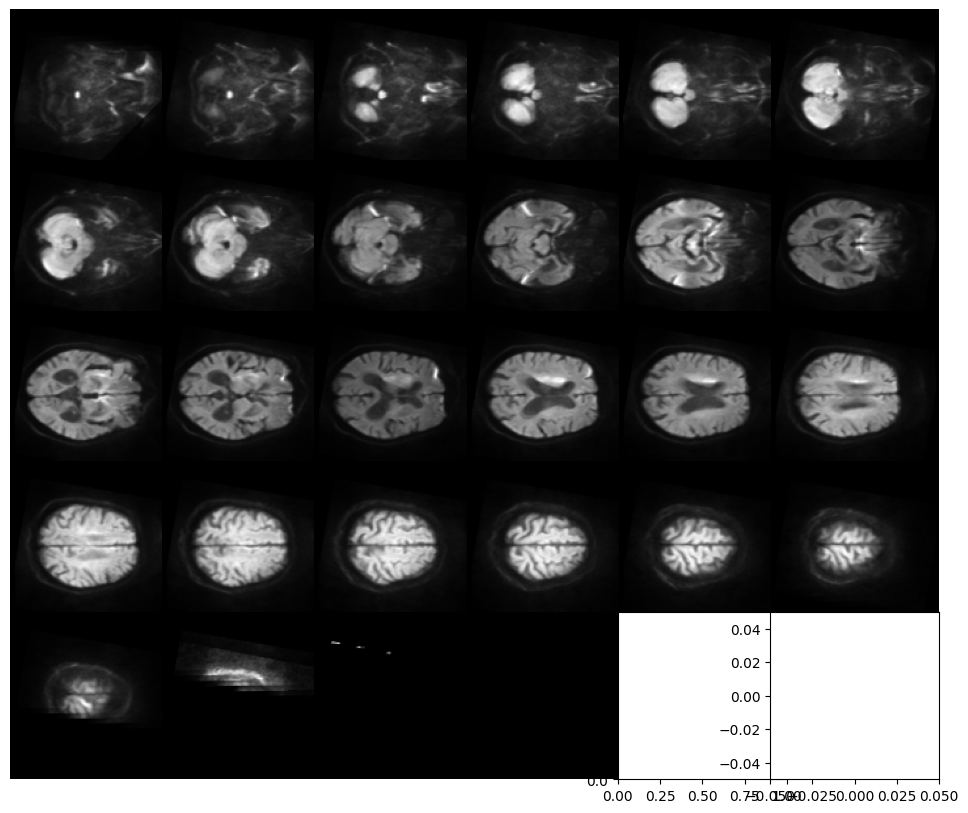

In [36]:

# Extract slices for patient zero
patient_zero_slices = X_in[10, :, :, :]

# Define grid size
rows, cols = 5, 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))

# Plot each slice
for i in range(rows * cols):
    if i < patient_zero_slices.shape[-1]:  # Ensure we don't exceed available slices
        ax = axes[i // cols, i % cols]
        ax.imshow(patient_zero_slices[:, :, i], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(False)

# Adjust layout to minimize spacing
plt.subplots_adjust(wspace=-0.1, hspace=-0.1)
plt.margins(0, 0)

plt.show()


# old files from bern
- prepare to be the same format as up

read in 

In [3]:
with h5py.File(DATA_DIR + "/data_bern_25_11_2020_preprocessed.h5", "r") as h5:
    X0 = h5["X_dwi"][:]
print(X0.shape, X0.min(), X0.max(), X0.mean(), X0.std())

(222, 128, 128, 64, 1) -7.217837989522173 39.758812613731685 -3.158197493145928 1.8809703357091876


In [4]:
old_df=pd.read_csv(DATA_DIR + "/data_bern_25_11_2020_wide_all_nihss.csv")
old_df


,p_id,age,sex,independent_pre_stroke,nihss_bl,nihss_24h,nihss_diff_bl_24h,intracranial_bleeding,tah_pre_stroke,antikoagulation_pre_stroke,...,S_Occ_rbv,S_Occ_tmax,S_Occ_tmip,S_Occ_ttp,S_Th_mtt,S_Th_rbf,S_Th_rbv,S_Th_tmax,S_Th_tmip,S_Th_ttp
0,442968,94.100000,1,0.0,4,0.0,-4.0,0,1,0,...,1.734783,2.697839,0.137407,36.053842,4.38,9.52,0.77,3.02,0.10,34.11
1,516341,53.500000,0,1.0,15,3.0,-12.0,0,1,0,...,2.246303,5.314702,0.073804,32.681875,4.12,21.01,1.40,2.37,0.07,30.73
2,653853,55.400000,1,1.0,5,13.0,8.0,0,0,0,...,3.625700,2.064731,0.283280,22.623514,3.70,22.89,1.46,0.92,0.18,21.29
3,768081,69.649315,1,1.0,16,4.0,-12.0,0,0,0,...,1.786534,5.928030,0.055423,48.298746,3.22,7.26,0.59,14.16,0.03,44.11
4,801402,84.400000,1,0.0,23,23.0,0.0,0,0,0,...,3.652100,2.242730,0.345533,23.808647,2.19,27.19,1.07,1.14,0.27,22.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217,14150158,81.100000,1,1.0,11,NaN,NaN,0,0,0,...,3.537241,3.001500,0.363907,27.720837,3.22,30.95,1.99,1.47,0.33,26.06
218,14239248,81.100000,1,1.0,13,3.0,-10.0,0,1,0,...,3.923033,2.598841,0.217408,26.352814,5.37,22.10,2.21,1.81,0.16,25.68
219,82147949,96.300000,0,1.0,17,8.0,-9.0,0,0,0,...,1.842840,4.356968,0.128217,36.740708,9.87,11.18,1.88,1.83,0.14,35.78
220,82341206,79.100000,1,1.0,6,12.0,NaN,0,1,0,...,3.947905,2.743382,0.266776,29.374911,5.68,34.47,3.54,1.89,0.27,28.38


In [8]:
import torch
import torch.nn.functional as F

downsample_shape=(128, 128, 28)
X0=X0.squeeze()
resized_patient_images = {}

for i, pid in enumerate(old_df['p_id']):
    print(f"Processing patient {pid} ({i+1}/{len(old_df['p_id'])})...")
    patient_image = X0[i]
    patient_tensor = torch.tensor(patient_image, dtype=torch.float32, device='cuda').unsqueeze(0).unsqueeze(0)
    resized_tensor = F.interpolate(patient_tensor, size=downsample_shape, mode='trilinear', align_corners=False)
    resized_numpy = resized_tensor.squeeze().cpu().numpy()  # Shape: (128, 128, 28)
    resized_patient_images[str(pid)] = resized_numpy
    
np.savez_compressed(os.path.join(DATA_DIR,'berner_daten_25_11_2020_dwi_skull_raw.npz'), **resized_patient_images)

Processing patient 442968 (1/222)...
Processing patient 516341 (2/222)...
Processing patient 653853 (3/222)...
Processing patient 768081 (4/222)...
Processing patient 801402 (5/222)...
Processing patient 830267 (6/222)...
Processing patient 876763 (7/222)...
Processing patient 911666 (8/222)...
Processing patient 975885 (9/222)...
Processing patient 991155 (10/222)...
Processing patient 996254 (11/222)...
Processing patient 1029355 (12/222)...
Processing patient 1071106 (13/222)...
Processing patient 1097032 (14/222)...
Processing patient 1192469 (15/222)...
Processing patient 1241478 (16/222)...
Processing patient 1305751 (17/222)...
Processing patient 1313428 (18/222)...
Processing patient 1344072 (19/222)...
Processing patient 1357840 (20/222)...
Processing patient 1397044 (21/222)...
Processing patient 1494589 (22/222)...
Processing patient 1495976 (23/222)...
Processing patient 1615629 (24/222)...
Processing patient 1679589 (25/222)...
Processing patient 1775707 (26/222)...
Proces

In [9]:
data = np.load(os.path.join(DATA_DIR,'berner_daten_25_11_2020_dwi_skull_raw.npz'))
X_in =  np.array([data[key].tolist() for key in data.files])

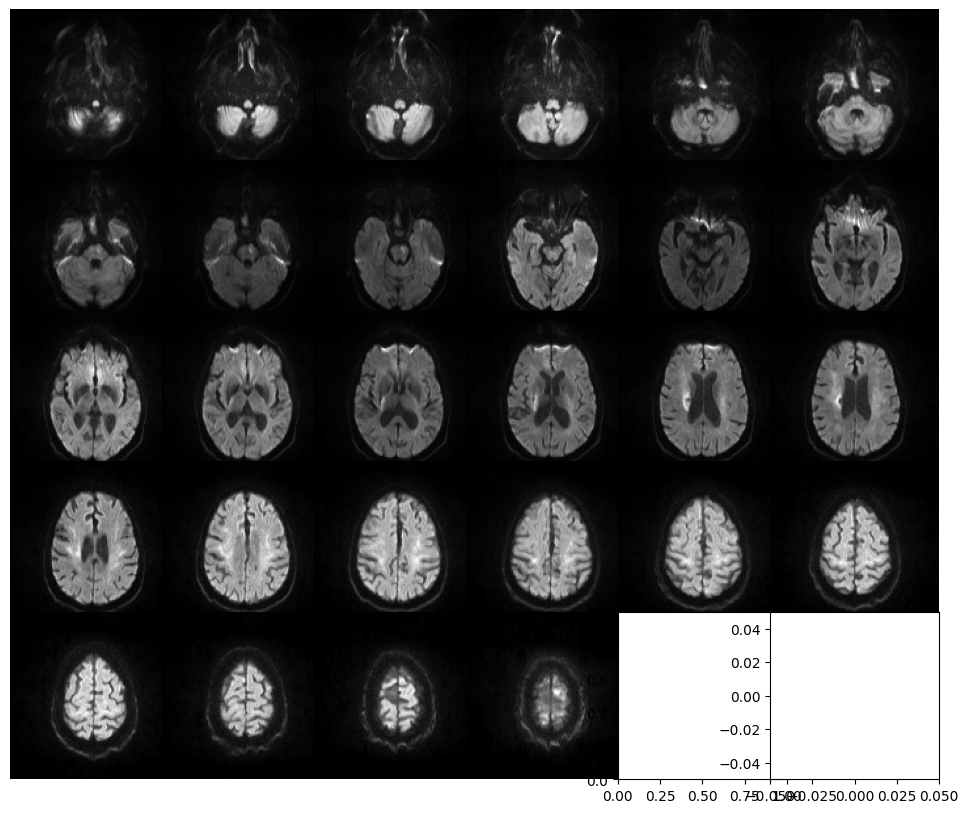

In [40]:

# Extract slices for patient zero
patient_zero_slices = X_in[10, :, :, :]

# Define grid size
rows, cols = 5, 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))

# Plot each slice
for i in range(rows * cols):
    if i < patient_zero_slices.shape[-1]:  # Ensure we don't exceed available slices
        ax = axes[i // cols, i % cols]
        ax.imshow(patient_zero_slices[:, :, i], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(False)

# Adjust layout to minimize spacing
plt.subplots_adjust(wspace=-0.1, hspace=-0.1)
plt.margins(0, 0)

plt.show()

In [10]:
old_df

,p_id,age,sex,independent_pre_stroke,nihss_bl,nihss_24h,nihss_diff_bl_24h,intracranial_bleeding,tah_pre_stroke,antikoagulation_pre_stroke,...,S_Occ_rbv,S_Occ_tmax,S_Occ_tmip,S_Occ_ttp,S_Th_mtt,S_Th_rbf,S_Th_rbv,S_Th_tmax,S_Th_tmip,S_Th_ttp
0,442968,94.100000,1,0.0,4,0.0,-4.0,0,1,0,...,1.734783,2.697839,0.137407,36.053842,4.38,9.52,0.77,3.02,0.10,34.11
1,516341,53.500000,0,1.0,15,3.0,-12.0,0,1,0,...,2.246303,5.314702,0.073804,32.681875,4.12,21.01,1.40,2.37,0.07,30.73
2,653853,55.400000,1,1.0,5,13.0,8.0,0,0,0,...,3.625700,2.064731,0.283280,22.623514,3.70,22.89,1.46,0.92,0.18,21.29
3,768081,69.649315,1,1.0,16,4.0,-12.0,0,0,0,...,1.786534,5.928030,0.055423,48.298746,3.22,7.26,0.59,14.16,0.03,44.11
4,801402,84.400000,1,0.0,23,23.0,0.0,0,0,0,...,3.652100,2.242730,0.345533,23.808647,2.19,27.19,1.07,1.14,0.27,22.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217,14150158,81.100000,1,1.0,11,NaN,NaN,0,0,0,...,3.537241,3.001500,0.363907,27.720837,3.22,30.95,1.99,1.47,0.33,26.06
218,14239248,81.100000,1,1.0,13,3.0,-10.0,0,1,0,...,3.923033,2.598841,0.217408,26.352814,5.37,22.10,2.21,1.81,0.16,25.68
219,82147949,96.300000,0,1.0,17,8.0,-9.0,0,0,0,...,1.842840,4.356968,0.128217,36.740708,9.87,11.18,1.88,1.83,0.14,35.78
220,82341206,79.100000,1,1.0,6,12.0,NaN,0,1,0,...,3.947905,2.743382,0.266776,29.374911,5.68,34.47,3.54,1.89,0.27,28.38


In [11]:
old_df_full = pd.read_csv(DATA_DIR + "/data_bern_25_11_2020_to_read_in.csv", encoding="ISO-8859-1")


/tmp/ipykernel_228437/3928401179.py:1: DtypeWarning: Columns (8,9) have mixed types. Specify dtype option on import or set low_memory=False.
  old_df_full = pd.read_csv(DATA_DIR + "/data_bern_25_11_2020_to_read_in.csv", encoding="ISO-8859-1")


In [12]:
old_df_full = old_df_full.groupby('p_id').first().reset_index()
old_df_full

,p_id,columns,instance_no,path,rows,sequence,modality,modality_no,folder,image,...,angio,thrombectomy,time_to_imaging,time_to_needle,time_to_groin_puncture,vessel_open_before_therapy,tici,tici_binary,toast,p_id_old
0,442968,192,1,D:\AIM_EXPORT\0000442968\13936379\0000442968_1...,192,ep2d_diff_3scan_trace_p2_ADC,ADC,2,13936379,1277138581,...,1,1,156.0,non,240.0,0,4,1,2,442968
1,516341,128,11,D:\AIM_EXPORT\0000516341\13946886\0000516341_1...,128,ep2d_diff_M128_b0_1000_DIN_ADC,ADC,1,13946886,1278003799,...,1,1,171.0,non,211.0,0,4,1,5,516341
2,653853,128,1,D:\AIM_EXPORT\0000653853\13960789\0000653853_1...,128,ep2d_diff_M128_b0_1000_DIN_ADC,ADC,1,13960789,1279008880,...,1,1,118.0,non,140.0,0,4,1,4,653853
3,768081,128,11,D:\AIM_EXPORT\0000768081\13961143\0000768081_1...,128,ep2d_diff_M128_b0_1000_DIN_ADC,ADC,1,13961143,1279073460,...,1,1,143.0,non,210.0,0,2,0,2,768081
4,801402,128,1,D:\AIM_EXPORT\0000801402\13961536\0000801402_1...,128,ep2d_diff_M128_b0_1000_DIN_ADC,ADC,1,13961536,1279145188,...,1,1,57.0,97,125.0,0,4,1,6,801402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217,14150158,128,1,D:\AIM_EXPORT\0014150158\14165039\0014150158_1...,128,ep2d_diff_M128_b0_1000_DIN_ADC,ADC,1,14165039,1292539647,...,1,1,730.0,non,837.0,0,3,1,6,14150158
218,14239248,384,1,D:\AIM_EXPORT\0014239248\14165390\0014239248_1...,384,ep2d_diff_4scan_trace_p2_s2_inkl.Neckcoil_ADC,ADC,6,14165390,1292611383,...,1,1,62.0,70,186.0,0,4,1,2,14239248
219,82147949,176,1,D:\AIM_EXPORT\0082147949\14165611\0082147949_1...,176,resolve_3scan_trace_tra_176_p2_ADC,ADC,4,14165611,1292651582,...,1,1,714.0,non,766.0,0,3,1,6,82147949
220,82341206,128,1,D:\AIM_EXPORT\0082341206\14165719\0082341206_1...,128,ep2d_diff_M128_b0_1000_DIN_ADC,ADC,1,14165719,1292668176,...,1,1,NaN,non,NaN,0,4,1,6,82341206


In [22]:
from sklearn.model_selection import StratifiedKFold


df = old_df_full
# if "mrs" not in df.columns:
#     raise ValueError("Column 'mrs' not found in the dataset")

df["unfavorable"] = (df["mrs_3months"] >= 3).astype(int)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
df[[f'fold{i}' for i in range(10)]] = ""

# Assign folds
for fold, (train_idx, test_idx) in enumerate(skf.split(df, df["mrs_3months"])):
    train_set, test_set = df.iloc[train_idx], df.iloc[test_idx]
    
    skf_val = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    val_size = int(0.1 * len(train_set))
    val_idx = np.random.choice(train_set.index, size=val_size, replace=False)
    val_set = train_set.loc[val_idx]
    
    df.loc[df.index.isin(test_set.index), f'fold{fold}'] = "test"
    df.loc[df.index.isin(val_set.index), f'fold{fold}'] = "val"
    df.loc[(df[f'fold{fold}'] == ""), f'fold{fold}'] = "train"

output_columns = [ "p_id", "mrs_3months", "unfavorable"] + [f'fold{i}' for i in range(10)]

df = df[output_columns]
df['p_idx']=df.index
# df.to_csv(os.path.join(DATA_DIR, 'data_bern_25_10_2020_10Fold_ids_test.csv'), index=False)
df

/home/bule/anaconda3/envs/berner_daten/lib/python3.9/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 5 members, which is less than n_splits=10.
  warnings.warn(
/tmp/ipykernel_228437/954079506.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['p_idx']=df.index


,p_id,mrs_3months,unfavorable,fold0,fold1,fold2,fold3,fold4,fold5,fold6,fold7,fold8,fold9,p_idx
0,442968,4,1,train,train,train,train,train,train,train,train,train,test,0
1,516341,2,0,train,train,train,train,train,train,train,train,train,test,1
2,653853,6,1,train,train,train,train,train,val,train,train,test,train,2
3,768081,1,0,train,train,train,train,train,train,train,train,test,train,3
4,801402,6,1,train,test,val,train,train,train,train,train,train,train,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217,14150158,4,1,train,test,train,train,train,train,val,train,train,train,217
218,14239248,0,0,train,train,val,test,train,train,train,train,train,val,218
219,82147949,6,1,train,train,train,train,test,train,train,train,train,train,219
220,82341206,2,0,train,train,train,train,train,train,train,test,train,train,220


In [24]:
filter_=df[df['fold0']=='train']
filter_['unfavorable'].value_counts()

unfavorable
0    97
1    83
Name: count, dtype: int64

In [ ]:
97/180

In [33]:
filter_=df[df['fold1']=='val']
filter_['unfavorable'].value_counts()
13/19

0.6842105263157895